In [17]:
import numpy as np
from scipy import linalg as la
import sympy as sp
sp.init_printing() 

#####
<font color="#2c3e50" size="6"><div style="
    font-family: sans-serif;
    font-size: 1.2em;
    font-weight: 700;
    line-height: 1.2;
    background-color: #d9e6f2;
    border-radius: 8px;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    padding: 0.5em 1em;
    margin-top: 1em;
    margin-bottom: 0.6em;
    box-shadow: 0 2px 6px rgba(0,0,0,0.1);
" align="center">
1.4 Linear Equations and Echelon Forms
</div></font>

Let’s revisit the definition of a linear combination:

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition.</strong> <br> Let  $ {\bf v}_1, {\bf v}_2, \cdots, {\bf v}_k $ be vectors in $\mathbb{R}^n$ and  $ c_1, c_2, \cdots, c_k$ be scalars. Then $$ {\bf y} = c_1{\bf v}_1+c_2{\bf v}_2+ \cdots + c_k{\bf v}_k$$ is called a <strong>linear combination</strong> of vectors $ {\bf v}_1, {\bf v}_2, \cdots, {\bf v}_k $ with weights $ c_1, c_2, \cdots, c_k$.
</div>

Sometimes we want to know whether a given vector ${\bf y}$ can be expressed as a linear combination of some vectors ${\bf v}_1, {\bf v}_2, \cdots, {\bf v}_k$. Let's look at a simple example.


Suppose ${\bf v}_1 = \begin{bmatrix} -2 \\ 1 \end{bmatrix}$, ${\bf v}_2 = \begin{bmatrix} 1 \\ 3 \end{bmatrix}$ and ${\bf y} = \begin{bmatrix} -4 \\ 9 \end{bmatrix}$ are vectors in $\mathbb{R}^2$. Can ${\bf y}$ be written as a linear combination of ${\bf v}_1$ and ${\bf v}_2$?


If so, then there are some scalars $x_1$ and $x_2$ such that

$$  x_1{\bf v}_1+x_2{\bf v}_2={\bf y}$$

Substituting the vectors:
$$ x_1\begin{bmatrix} -2 \\ 1 \end{bmatrix}+x_2 \begin{bmatrix} 1 \\ 3 \end{bmatrix} = \begin{bmatrix}  -4 \\ 9 \end{bmatrix}$$

The equation above is usually referred to as a **vector equation**. Its solutions are all pairs $(s_1, s_2)$ such that substituting $x_1=s_1$ and $x_2=s_2$ into the equation makes it true.

Let's simplify the left-hand side:
$$ \begin{bmatrix} -2x_1 \\1x_1 \end{bmatrix}+\begin{bmatrix} 1x_2 \\ 3x_2 \end{bmatrix}= \begin{bmatrix}  -4 \\ 9 \end{bmatrix}$$
$$ \begin{bmatrix} -2x_1 +1x_2 \\1x_1 +3x_2\end{bmatrix}= \begin{bmatrix}  -4 \\ 9 \end{bmatrix}$$

Since two vectors are equal if and only if their corresponding entries are equal, we get a system of two linear equations with two unknowns:

$$\left\{\begin{array}{l}
  -2x_1 &+&1x_2 &=& -4 \\
  1x_1 &+&3x_2 &=& 9
\end{array}\right.$$

The solution set of this system is exactly the same as the solution set of the vector equation. This system of linear equations is simple enough to solve using techniques from a college algebra class such as elimination or substitution methods. However, notice that if we had $k$ vectors ${\bf v}_1 \cdots {\bf v}_k$ in a higher-dimensional space $\mathbb{R}^n$, then this would produce a larger system with $n$ equations and $k$ unknowns. While basic algebra techniques still work, they quickly become cumbersome. To handle larger systems efficiently, we need a systematic approach. To build that, let’s first revisit what a linear equation is.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition.</strong> <br> A <strong> linear equation </strong> in $n$ variables $x_1,x_2, \cdots, x_n$ is an equation that can be written in the form $$a_1x_1+a_2x_2+ \cdots + a_nx_n=b,$$ where the <strong> coefficients </strong> $a_1, a_2, \cdots, a_n$ and the <strong> constant term </strong> $b$ are constants.
</div>

A linear equation in two variables $a_1x_1+a_2x_2=b$ represents a line in $\mathbb{R}^2$ (It may look more familiar if we rename the variables and coefficients:  $ax+by=c$)

A linear equation in three variables $a_1x_1+a_2x_2+a_3x_3=b$ represents a plane in $\mathbb{R}^3$.

A linear equation in more than three variables represents an object that we usually call a *hyper-plane* in appropriate Euclidean space.

---
**<font color="red">Example 1</font>**

These are all linear equations:  
$2x-5y=1$,  
$4x_1-4x_2+x_3=0$,  
$ \frac{1}{2}x_1+\sqrt{2}x_2=\pi$,   
$x_1+3x_3=x_2-5x_4$  


These are not linear equations because they contain powers, products of variables, or nonlinear functions: 
$\sin(x)+y=0$,  
$x+y^2=1$,  
$x_1x_2+x_3=1$,   
$\sqrt{x_1}+x_2=1$.

---



A finite set of linear equations is called a **system of linear equations**, or simply a **linear system**. A solution to a linear system with $n$ unknowns $x_1, x_2, \cdots, x_n$ is an ordered list of numbers $(s_1, s_2, \cdots, s_n)$ such that substituting $$x_1=s_1, \text{ } x_2=s_2,\text{ } \cdots,  \text{ }x_n=s_n$$ into every equation makes all equations true. Since solutions are ordered lists of numbers, we can naturally represent them as vectors. The **solution set** is the set of all solutions to the given linear system. Two linear systems are called **equivalent** if they have the same solution set.

---

Since linear combination of vectors can also be written as matrix-vector product, we can express system of linear equations as **matrix equation** $A{\bf x}={\bf b}$, where the matrix $A$ contains the coefficients, and vector ${\bf b}$ consists of all constant terms. Therefore, we have three types of equations that are equivalent. 

$$\left\{\begin{array}{l}
  a_{11}x_1+a_{12}x_2+ \cdots + a_{1n}x_n=b_1 \\
  a_{21}x_1+a_{22}x_2+ \cdots + a_{2n}x_n=b_2 \\
  \vdots \\
  a_{m1}x_1+a_{m2}x_2+ \cdots + a_{mn}x_n=b_m \\
\end{array}\right. \Leftrightarrow 
\underbrace{x_1 \begin{bmatrix} a_{11} \\ a_{21} \\ \vdots \\ a_{m1}\end{bmatrix}+x_2 \begin{bmatrix} a_{12} \\ a_{22} \\ \vdots \\ a_{m2}\end{bmatrix}+ \cdots + x_n \begin{bmatrix} a_{1n} \\ a_{2n} \\ \vdots \\ a_{mn}\end{bmatrix} =\begin{bmatrix} b_{1} \\ b_{2} \\ \vdots \\ b_{m}\end{bmatrix}}_{\large x_1{\bf a}_1 + x_2{\bf a}_2 + \cdots x_n{\bf a}_n={\bf b}}
\Leftrightarrow 
\underbrace{\begin{bmatrix} a_{11} & a_{12} & \cdots & a_{1n} \\ a_{21} & a_{22} & \cdots & a_{2n} \\ \vdots & \vdots & \ddots & \vdots \\ a_{m1} & a_{m2} & \cdots & a_{mn} \end{bmatrix}\begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_n \end{bmatrix}=\begin{bmatrix} b_{1} \\ b_{2} \\ \vdots \\ b_{m}\end{bmatrix}}_{\large A{\bf x}={\bf b}}$$


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem.</strong> <br> Let $A$ be an $m \times n$ matrix with columns ${\bf a}_1, {\bf a}_2, \cdots , {\bf a}_n$, and let ${\bf b}$ be a vector in $\mathbb{R}^m$. Then, the matrix equation $$A{\bf x}={\bf b}$$ has the same solution set as a vector equation $$x_1{\bf a}_1 + x_2{\bf a}_2 + \cdots +x_n{\bf a}_n={\bf b},$$ which in turn has the same solution set as the corresponding linear system 
    $$\left\{\begin{array}{l}
  a_{11}x_1+a_{12}x_2+ \cdots + a_{1n}x_n=b_1 \\
  a_{21}x_1+a_{22}x_2+ \cdots + a_{2n}x_n=b_2 \\
  \vdots \\
  a_{m1}x_1+a_{m2}x_2+ \cdots + a_{mn}x_n=b_m \\
\end{array}\right.$$
</div>

An equation of the form $A{\bf x}={\bf b}$ is called **homogeneous** if ${\bf b}={\bf 0}$; otherwise, it is called **non-homogeneous**. 

In the homogeneous case $A{\bf x}={\bf 0}$, the zero vector ${\bf 0}$ is always a solution, regardless of the matrix $A$, since $A{\bf 0}={\bf 0}$. This solution is called the **trivial solution**. Because every homogeneous equation has the trivial solution, we are usually interested in knowing whether it has non-trivial solutions. Note that a non-homogeneous equation $A{\bf x}={\bf b}$ with ${\bf b}\neq {\bf 0}$ cannot have the trivial solution.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Solution Sets for Linear System</b>
</div></font> 

Let's look at the possible solution sets.

---
**<font color="red">Example 2 (Linear system with 2 equations and 2 unknowns)</font>**


In this case, each equation is a line in $\mathbb{R}^2$. The solution set will consist of all points in $\mathbb{R}^2$ that lie on both lines. This leads to three possible cases:

1. Lines are distinct and parallel. In this case, we have no solution.

2. Lines are the same. In this case, we have infinitely many solutions. Every point on the line is a solution.

3. Lines intersect at a single point. In this case, we have exactly one solution.

Notice that exactly two solutions are impossible since any two lines that share at least two points must be the same line.

<center> <img src="data:image/png;base64,  ...
 " width="80%">
<br>
  <em> <strong>(a) </strong> No solution   <strong>(b) </strong> Infinitely many solutions   <strong>(c) </strong> Exactly one solution </em></center>

---
**<font color="red">Example 3 (Linear system with 3 equations and 3 unknowns)</font>**


In this case, each equation is a plane in $\mathbb{R}^3$. The solution set consists of all points in $\mathbb{R}^3$ that lie on all three planes. This leads to several possible geometric configurations (see the figure below), but there are only three possible types of solution sets:

1. No solution.

2. Infinitely many solutions.

3. Exactly one solution.

<center> <img src="data:image/png;base64,  ...
 " width="80%"> <em> <br><strong> (a), (b), (d), (e) </strong> No solution<br> <strong> (c) </strong> Infinitely many solutions. Solutions form a plane<br> <strong> (f), (g) </strong> Infinitely many solutions. Solutions form a line <br> <strong> (h) </strong> One solution
</em></center>

The three cases illustrated in both examples are the only possibilities for any linear system.

A linear system is **inconsistent** if it has no solution. Otherwise, it is called **consistent**. If a linear system is consistent, then it has either a unique solution or infinitely many solutions.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Augmented Matrix</b>
</div></font> 

Before we try to solve a linear system, we should rewrite it in a more efficient form. Let's go back to our system from the start of this chapter:
$$\left\{\begin{array}{l}
  -2x_1 &+&1x_2 &=& -4 \\
  1x_1 &+&3x_2 &=& 9
\end{array}\right.$$

Notice that when we align the variables, then the only things that matter are the coefficients and constant terms. We can arrange the coefficients in a matrix form and the constant terms in a vector form as follows:

$$A=\begin{bmatrix} -2 & 1 \\ 1 & 3 \end{bmatrix}, \text{   } {\bf b}=\begin{bmatrix} -4 \\ 9 \end{bmatrix}$$

In this case, the first column of $A$ corresponds to the first variable $x_1$ and the second column corresponds to the second variable $x_2$. Each row of the matrix $A$ corresponds to the left side of each equation in the linear system. Such matrix $A$ is called a **coefficient matrix** and vector ${\bf b}$ is called a **constant vector**. (Note that these are exactly the same $A$ and ${\bf b}$ that we get if we rewrite linear system as a matrix equation $A{\bf x}={\bf b}$.)

If we append the constant vector to the coefficient matrix, we get **augmented matrix**:
$$\left[
\begin{array}{cc|c}
-2 & 1  & -4 \\ 1 & 3  & 9
\end{array}
\right]$$

We placed a vertical bar to separate left and right sides of equations. Partitioning matrix like that is purely for visual aid.


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Elementary Row Operations</b>
</div></font> 

In a college algebra course, when solving a linear system, students typically apply simple operations to the equations, such as multiplying an equation by a nonzero constant or adding one equation to another to eliminate variables. These steps transform the original system into an equivalent system whose solution is easier to identify. We now introduce analogous operations, called **elementary row operations**, which are applied to an augmented matrix. These operations mirror the allowed manipulations of a linear system and do not change its solution set.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Elementary Row Operations  </strong> <br>
    1. <strong>Interchange</strong>: Interchange any two rows <br>
    2. <strong>Scale</strong>: Multiply any row by a non-zero number <br>
    3. <strong>Replace</strong>: Replace a row with a sum of itself and a multiple of another row
</div>

Each of these corresponds directly to an operation on a system of linear equations that preserves the solution set. Specifically, we may interchange any two equations, multiply any equation by a nonzero constant, or add a multiple of one equation to another. Using these three operations, we can solve any linear system.

To describe row operations concisely, we use the following notation. Let $R_i$ denote the $i$-th row of a matrix, then:

1. $R_i \leftrightarrow R_j $ denotes interchange of the $i$-th and $j$-th rows.
2. $kR_i$ denotes scaling the $i$-th row by $k$.
3. $R_i+kR_j$ denotes replacing the $i$-th row with a sum of itself and the $j$-th row multiplied by $k$.

The process of solving a linear system using elementary row operations is called **row reduction**. 


Let's use row reduction to solve linear system above. In addition to working with the augmented matrix, we will also keep track of the corresponding changes in the system of linear equations.

$\begin{align*}
\left[
\begin{array}{cc|c}
-2 & 1  & -4 \\ 1 & 3  & 9
\end{array}
\right]
& \qquad\text{          }\qquad &
\left\{\begin{array}{l}
  -2x_1 &+&1x_2 &=& -4 \\
  1x_1 &+&3x_2 &=& 9
\end{array}\right.
\end{align*}$

Let's interchange two rows ( $\color{HotPink}{R_1 \leftrightarrow R_2}$ ):

$\begin{align*}
\left[
\begin{array}{cc|c}
1 & 3  & 9 \\ -2 & 1  & -4 
\end{array}
\right]
& \qquad\text{          }\qquad &
\left\{\begin{array}{l}
      1x_1 &+&3x_2 &=& 9 \\
  -2x_1 &+&1x_2 &=& -4 
\end{array}\right.
\end{align*}$

Using replacement operation, let's add the first row multiplied by 2 to the second row ( <font color="HotPink">$ R_2+2R_1 $</font> ):

$\begin{align*}
\left[
\begin{array}{cc|c}
1 & 3  & 9 \\ 0 & 7  & 14 
\end{array}
\right]
& \qquad\text{          }\qquad &
\left\{\begin{array}{l}
      1x_1 &+&3x_2 &=& 9 \\
   & &7x_2 &=& 14 
\end{array}\right.
\end{align*}$

Now, let's scale the second row by $1/7$ ( <font color="HotPink">$\frac{1}{7}R_2 $</font> ):

$\begin{align*}
\left[
\begin{array}{cc|c}
1 & 3  & 9 \\ 0 & 1  & 2 
\end{array}
\right]
& \qquad\text{          }\qquad &
\left\{\begin{array}{l}
      1x_1 &+&3x_2 &=& 9 \\
   & &1x_2 &=& 2 
\end{array}\right.
\end{align*}$

We can already see that $x_2=2$. We could take that and substitute into the first equation to get $x_1$. This is called **Gaussian elimination**. Alternatively, we can continue to do row operations "backwards" to get to the final solution. This is called **Gauss-Jordan elimination**. Let's continue with row operations. 

We add the second row multiplied by $-3$ to the first row ( <font color="HotPink">$R_1+(-3)R_2 $</font> ):

$\begin{align*}
\left[
\begin{array}{cc|c}
1 & 0  & 3 \\ 0 & 1  & 2 
\end{array}
\right]
& \qquad\text{          }\qquad &
\left\{\begin{array}{l}
      1x_1 & & &=& 3 \\
   & &1x_2 &=& 2 
\end{array}\right.
\end{align*}$

Now we can see that the solution is $\left\{\begin{array}{l}
x_1 = 3 \\
x_2 = 2 
\end{array}\right.$

We can write this more efficiently in the vector form as ${\bf x}=\begin{bmatrix} 3\\2 \end{bmatrix}$.

We can finally answer our original question:  Can ${\bf y} = \begin{bmatrix} -4 \\ 9 \end{bmatrix}$ be written as a linear combination of ${\bf v}_1 = \begin{bmatrix} -2 \\ 1 \end{bmatrix}$ and ${\bf v}_2 = \begin{bmatrix} 1 \\ 3 \end{bmatrix}$?

The answer is yes. In fact, ${\bf y}=3{\bf v}_1+2{\bf v}_2$

---

If a matrix $A$ can be transformed into a matrix $B$ using only elementary row operations, then we say that $A$ and $B$ are **row equivalent** and denote it by $A \sim B$. In the example above, all of the matrices on the left-hand side are row equivalent. Row-equivalent augmented matrices correspond to equivalent linear systems and therefore have the same solution set. Our goal, when solving a linear system, is to start with its augmented matrix and apply elementary row operations to transform it into a row-equivalent matrix that is simpler and from which the solution can be read directly. During this process, two particularly important types of matrices arise. The first appears at the stage where Gaussian elimination can be applied. The second is the final matrix from which we can immediately read off the solution. We now define these special forms and then describe how to obtain them in the general case.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Row Echelon Forms</b>
</div></font> 

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition.</strong> <br> A <strong>leading entry</strong> of a row in a matrix is the first non-zero entry in that row.
</div>


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition.</strong> <br> A matrix is in <strong>row echelon form (REF)</strong> if it satifies the following two conditions:  <br>
<strong>1. </strong> All zero rows (rows consisting entirely of zeros) are at the bottom of the matrix.  <br>
<strong>2. </strong> In each nonzero row, the leading entry appears in a column strictly to the right of the leading entry in the row above it.
</div>



When we row-reduce a matrix $A$ to REF, we call the resulting matrix an **echelon form of A**. Matrices in REF have a characteristic staircase pattern of leading entries, with zeros below each leading entry:


$$
\require{color}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\begin{align*}
\left[
\begin{array}{}
\hl{1} & \hl{3}  & \hl{9} \\ 0 & \hl{7}  & \hl{14}  
\end{array}
\right]
\text{,}\qquad 
\left[
\begin{array}{}
\hl{2} & \hl{-3}  & \hl{2} \\ 0 & \hl{1}  & \hl{1}  \\  0 & 0 & 0
\end{array}
\right]
\text{,}\qquad 
\left[
\begin{array}{}
\hl{1} & \hl{0}  & \hl{2} & \hl{2} \\ 0 & 0  & \hl{1}  & \hl{2} \\  0 & 0 & 0 & \hl{7}
\end{array}
\right]
\text{,}\qquad 
\left[
\begin{array}{}
0 & \hl{1}  & \hl{3} & \hl{4} \\ 0 & 0  & \hl{1}  & \hl{2} \\  0 & 0 & 0 & \hl{7}
\end{array}
\right]
\end{align*}$$

If an augmented matrix is row reduced to REF, we can then use Gaussian elimination (back-substitution) to obtain the solution to the corresponding linear system.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition.</strong> <br> A REF matrix is in <strong>reduced row echelon form (RREF)</strong> if, in addition to the REF conditions, it satisfies the following two conditions:  <br>
<strong>3. </strong> All leading entries are $1$.  <br>
<strong>4. </strong> All entries above leading entries are $0$.
</div>



When we row reduce a matrix to RREF, we call the resulting matrix the **reduced row echelon form of A**. Here are examples of matrices in RREF with leading entries highlighted:

$$
\require{color}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\begin{align*}
\left[
\begin{array}{}
\hl{1} & 0  & 3 \\ 0 & \hl{1}  & 2  
\end{array}
\right]
\text{,}\qquad 
\left[
\begin{array}{}
\hl{1} & 0 & 2 \\ 0 & \hl{1}  & 1  \\  0 & 0 & 0
\end{array}
\right]
\text{,}\qquad 
\left[
\begin{array}{}
\hl{1} & 1  & 0 & -7 & 0 & 1 \\ 0 & 0  & \hl{1}  & 1 & 0 & -1 \\  0 & 0 & 0 & 0 & \hl{1} & 3
\end{array}
\right]
\text{,}\qquad 
\left[
\begin{array}{}
0 & \hl{1}  & 0 & 0 \\ 0 & 0  & \hl{1}  & 0 \\  0 & 0 & 0 & \hl{1}
\end{array}
\right]
\end{align*}$$


Any given matrix has many different echelon forms, but it has only one reduced row echelon form. Although a matrix may have multiple echelon forms, they all share an important property: the leading entries occur in exactly the same positions in every echelon form. These positions play a crucial role in solving the corresponding linear system.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition.</strong> <br> A <strong>pivot position</strong> of a matrix $A$ is a position that contains a leading entry in an echelon form of $A$. A column that contains a pivot position is called a <strong>pivot column</strong>.
</div>

All leading entries that we highlighted in the above example are in fact pivots.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #dd8452;
    background-color: rgba(250,100,60,0.16);
    margin: 0.4em 0;
">
<strong>⚠️Caution.</strong> A pivot is not a value, but a position.
</div>

Note that every row and every column contain at most one pivot position.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Vector Parametric Form for the Solution</b>
</div></font> 

When our augmented matrix is in RREF, we can read off the solution. Let's assume that the four matrices above are augmented matrices and let's write the solution set for each. 

**1.** The first matrix is the example we have been working with throughout this chapter.

$$\begin{align*}
\left[
\begin{array}{cc|c}
1 & 0  & 3 \\ 0 & 1  & 2 
\end{array}
\right]
 \qquad \Rightarrow \qquad 
\left\{\begin{array}{l}
      1x_1 & & &=& 3 \\
   & &1x_2 &=& 2 
\end{array}\right.
\qquad  \Rightarrow \qquad
{\bf x}=\begin{bmatrix} 3\\ 2 \end{bmatrix}
\end{align*}$$

**2.** The second matrix is similar to the first one. We have two variables here as well.
  
$$\begin{align*}
\left[
\begin{array}{cc|c}
1 & 0  & 2 \\ 0 & 1  & 1  \\ 0 & 0 & 0
\end{array}
\right]
 \qquad \Rightarrow \qquad 
\left\{\begin{array}{l}
      1x_1 & & &=& 2 \\
   & &1x_2 &=& 1 \\
   & & 0 &=& 0
\end{array}\right.
\qquad  \Rightarrow \qquad
{\bf x}=\begin{bmatrix} 2\\ 1 \end{bmatrix}
\end{align*}$$


**3.** This example is slightly more involved because the system has five variables.

 $$\begin{align*}
\left[
\begin{array}{ccccc|c}
1 & 1  & 0 & -7 & 0 & 1 \\ 0 & 0  & 1  & 1 & 0 & -1 \\  0 & 0 & 0 & 0 & 1 & 3
\end{array}
\right]
 \qquad \Rightarrow \qquad 
\left\{\begin{array}{l}
      x_1 & +  x_2 &  & - 7x_4 &  & =& 1 \\
   & &x_3 & +x_4 & &=& -1 \\
   & &  & &x_5 &=& 3
\end{array}\right.
\end{align*}$$

In this system, the variables fall into two categories: those that appear in leading positions and those that do not. Variables corresponding to leading entries are called **leading variables** (or basic variables), while the remaining variables are called **free variables**. 

To describe the solution, we rewrite the system so that each leading variable is expressed in terms of the free variables and constants. This is done by moving all terms involving free variables to the right-hand side. We introduce standard parameter notation by assigning a parameter to each free variable. In this case, we let $$ x_2=s \text{, and } x_4=t,$$
where $s$ and $t$ are real numbers. Substituting these parameters into the system gives

$$\require{color}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\begin{align*}
\left\{\begin{array}{l}
      \hl{x_1} & +  x_2 &  & - 7x_4 &  & =& 1 \\
   & &\hl{x_3} & +x_4 & &=& -1 \\
   & &  & &\hl{x_5} &=& 3
\end{array}\right.
 \qquad \Rightarrow \qquad 
\left\{\begin{array}{l}
\hl{x_1}  & =& 1 - x_2 +7x_4 \\
x_2 & =& x_2\\
\hl{x_3}  &=& -1  - x_4\\
x_4 & =& x_4\\
\hl{x_5} &=& 3
\end{array}\right.
 \qquad \Rightarrow \qquad 
\left\{\begin{array}{l}
{x_1}  & =& 1 - s +7t \\
x_2 & =& s\\
{x_3}  &=& -1  - t\\
x_4 & =& t\\
{x_5} &=& 3
\end{array}\right.
\end{align*}$$

This is called the **parametric form** of the solution. We can also rewrite it in **vector parametric form**:

$${\bf x}= 
\begin{bmatrix}
x_1 \\
x_2\\
x_3\\
x_4\\
x_5
\end{bmatrix}=
\begin{bmatrix}
1 &- s &+7t \\
&s&\\
-1&  &- t\\
 &&t\\
 3&&
\end{bmatrix}
=\begin{bmatrix}
1  \\
0\\
-1\\
 0\\
 3
\end{bmatrix}+
\begin{bmatrix}
- s \\
s\\
0\\
 0\\
 0
\end{bmatrix}+
\begin{bmatrix}
7t \\
0\\
- t\\
 t\\
 0
\end{bmatrix} =\require{bbox}\bbox[10px, border: 2px solid HotPink]{
\begin{bmatrix}
1  \\
0\\
-1\\
 0\\
 3
\end{bmatrix}+
s\begin{bmatrix}
- 1\\
1\\
0\\
 0\\
 0
\end{bmatrix}+
t\begin{bmatrix}
7 \\
0\\
- 1\\
 1\\
 0
\end{bmatrix}}$$

This form makes it clear that the system has infinitely many solutions. Each choice of the parameters $s$ and $t$ produces a solution by forming a linear combination of the vectors and adding it to the constant vector.


**4.** This case is simple.

$$\require{color}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\begin{align*}
\left[
\begin{array}{ccc|c}
0 & 1  & 0 & 0 \\ 0 & 0  & 1  & 0 \\  0 & 0 & 0 & \hl{1}
\end{array}
\right]
 \qquad \Rightarrow \qquad 
\left\{\begin{array}{l}
    x_2 & & &=& 0 \\
   & &x_3 &=& 0 \\
   & & 0 &=& 1
\end{array}\right.
\end{align*}$$

The last equation, $0=1$ makes no sense, and therefore cannot be satisfied. As a result, this system has no solutions; it is an inconsistent system. In terms of matrices, this situation occurs when the augmented matrix contains a row whose leading entry appears in the last (augmented) column.

---
We can summarize our findings:

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem </strong> <br><strong>1. </strong> A linear system is inconsistent if and only if its augmented matrix contains a pivot in the last (augmented) column. <br>
<strong>2. </strong> A consistent linear system has infinitely many solutions if it has at least one free variable.
</div>

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Row Reduction Algorithm</b>
</div></font> 

Let's introduce an efficient algorithm for reducing a matrix to REF or RREF.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Algorithm for reducing matrix to REF </strong> <br>
<strong>1. </strong> Move all zero rows to the bottom of the matrix.<br>  
<span style="line-height: 1.6; display: inline-block;"><strong>2. </strong>  Identify the leftmost nonzero column.  If necessary, interchange rows to move a nonzero entry to the top of this column. (If possible, choose $1$ or $-1$ for convenience.) This entry becomes the first pivot. </span><br>  
<strong>3. </strong> Use the pivot to eliminate all entries below it, creating zeros beneath the pivot.<br>  
<span style="line-height: 1.6; display: inline-block;"> <strong>4. </strong>  Cover the row containing the pivot and repeat the process on the remaining submatrix, starting with the columns to the right of the pivot column. If the remaining submatrix is zero, stop. </span><br>
</div>


When no further steps are possible, the resulting matrix is in row echelon form (REF). To obtain reduced row echelon form (RREF), continue with the following steps:

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Algorithm for reducing a matrix in REF to RREF </strong> <br>
<span style="line-height: 1.6; display: inline-block;"><strong>5. </strong> Starting with the bottommost pivot, scale its row so that the pivot equals, then eliminate all entries above it in the pivot column. (These two operations can be performed in either order). </span> <br>
<strong>6. </strong> Move to the pivot in the row above and repeat Step 5 until all pivot columns have zeros everywhere except at their pivots, which equal $1$.
</div>



We stop when no further steps are possible. The resulting matrix is in the reduced row echelon form (RREF).

Practicing these steps will help you develop an efficient and reliable workflow. Following this order minimizes the number of operations and reduces the likelihood of arithmetic errors. Using pivots or row operations in a different order typically requires more steps and increases the chance of mistakes.


Let's now see this algorithm in action.

---
**<font color="red">Example 4</font>**

Solve the following linear system.

$$\left\{\begin{array}{l}
  2x_1 &+6x_2 &-2x_3 &  &= 1 \\
  x_1 &+2x_2 &-3x_3 & +x_4 &= 0 \\
  3x_1 &  &-21x_3 &+7x_4 & =3
\end{array}\right.$$

**Solution.**

We start by converting the linear system into its augmented matrix.
$$\begin{align*}
\left[
\begin{array}{cccc|c}
2 & 6  & -2 & 0 & 1 \\ 1 & 2  & -3  & 1 & 0 \\  3 & 0 & -21 & 7 & 3
\end{array}
\right]
\end{align*}$$

Next we apply the first algorithm to get an echelon form. Below we highlight pivot positions as we find them in orange and entries to be eliminated in blue.

$$\require{color}\require{bbox}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\newcommand{\hly}[1]{\bbox[DarkTurquoise, 2pt]{#1}}
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{2} & 6  & -2 & 0 & 1 \\ 1 & 2  & -3  & 1 & 0 \\  3 & 0 & -21 & 7 & 3
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{R_1 \leftrightarrow R_2}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & 1 & 0 \\ \hly{2} & 6  & -2 & 0 & 1   \\ \hly{3} & 0 & -21 & 7 & 3
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{R_2 + 3R_1}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & 1 & 0 \\ \hly{0} & 2  & 4 & -2 & 1  \\   \hly{3} & 0 & -21 & 7 & 3
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{R_3 + (-3)R_1}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & 1 & 0 \\ \hly{0} & 2  & 4 & -2 & 1  \\ \hly{0} & -6 & -12 & 4 & 3
\end{array}}\end{array}
\right]
$$

We can now identify the second pivot and we can ignore the first row.

$$\require{color}\require{bbox}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\newcommand{\hly}[1]{\bbox[DarkTurquoise, 2pt]{#1}}
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & 1 & 0 \\ 0 & \hl{2}  & 4 & -2 & 1  \\ 0 & \hly{-6} & -12 & 4 & 3
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{R_3 + 3R_2}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & 1 & 0  \\ 0 & \hl{2}  & 4 & -2 & 1  \\  0 & \hly{0} & 0 & -2 & 6
\end{array}}\end{array}
\right]
=\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & 1 & 0  \\ 0 & \hl{2}  & 4 & -2 & 1  \\  0 & 0 & 0 & \hl{-2} & 6
\end{array}}\end{array}
\right]
$$

Now we can see that the first, second and forth columns are pivot columns. Let's continue with the backward phase to obtain the reduced row echelon form. Recall that we start with the bottommost pivot and try to make entries above it a zero. 

$$\require{color}\require{bbox}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\newcommand{\hly}[1]{\bbox[DarkTurquoise, 2pt]{#1}}
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & \hly{1} & 0  \\ 0 & 2  & 4 & \hly{-2} & 1  \\  0 & 0 & 0 & \hl{-2} & 6
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{-\frac{1}{2}R_3}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & \hly{1} & 0  \\ 0 & \hl{2}  & 4 & \hly{-2} & 1  \\  0 & 0 & 0 & \hl{1} & -3
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{R_2+2R_3}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 2  & -3  & \hly{1} & 0  \\ 0 & \hl{2}  & 4 & \hly{0} & -5  \\  0 & 0 & 0 & \hl{1} & -3
\end{array}}\end{array}
\right]$$ $$
\stackrel{\color{HotPink}{R_1+(-1)R_3}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & \hly{2}  & -3  & \hly{0} & 3  \\ 0 & \hl{2}  & 4 & \hly{0} & -5  \\  0 & 0 & 0 & \hl{1} & -3
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{R_1+(-1)R_2}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & \hly{0}  & -7  & \hly{0} & 8  \\ 0 & \hl{2}  & 4 & \hly{0} & -5  \\  0 & 0 & 0 & \hl{1} & -3
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{\frac{1}{2}R_2}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cccc|c}
\hl{1} & 0  & -7  & 0 & 8  \\ 0 & \hl{1}  & 2 & 0 & -5/2  \\  0 & 0 & 0 & \hl{1} & -3
\end{array}}\end{array}
\right]
$$

Now that we have obtained RREF, we can write our answer. We have one free variable, $x_3$. Let $x_3=t$. Then
$$
\left\{\begin{array}{l}
\hl{x_1}  & =& 8 +7x_3 \\
\hl{x_2} & =& -5/2 -2x_3\\
x_3  &=&  x_3\\
\hl{x_4} & =& -3
\end{array}\right.
 \qquad \Rightarrow \qquad 
\left\{\begin{array}{l}
{x_1}  & =& 8 +7t \\
{x_2} & =& -5/2 -2t\\
x_3  &=&  t\\
{x_4} & =& -3
\end{array}\right.$$


Our final answer is 

$${\bf x}= 
\begin{bmatrix}
x_1 \\
x_2\\
x_3\\
x_4
\end{bmatrix}=
\begin{bmatrix}
8 &+7t \\
-5/2 &-2t\\
 & t\\
 -3&
\end{bmatrix}
=\begin{bmatrix}
8  \\
-5/2\\
 0\\
 -3
\end{bmatrix}+
\begin{bmatrix}
7t \\
-2t\\
1\\
 0
\end{bmatrix} =\require{bbox}\bbox[10px, border: 2px solid HotPink]{
\begin{bmatrix}
8  \\
-5/2\\
 0\\
 -3
\end{bmatrix}+
t\begin{bmatrix}
7\\
-2\\
1\\
 0
\end{bmatrix}}$$

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>RREF in Python</b>
</div></font> 

Unfortunately, neither NumPy nor SciPy has a built-in function to find RREF of a matrix. We can use SymPy library instead. SymPy is a symbolic mathematics library that can compute exact results, although it is generally much slower than NumPy for numerical calculations. In order to use SymPy, we have to create a SymPy matrix. We can either create it from scratch or, if we have a NumPy array, we can convert it to a SymPy matrix.

Let's create a SymPy matrix for a matrix from our last example and then use `.rref()` method to find its reduced row echelon form.

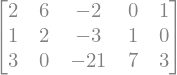

In [5]:
A=sp.Matrix([[2,6,-2,0,1],[1,2,-3,1,0],[3,0,-21,7,3]])
A

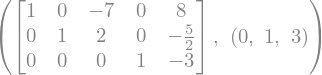

In [6]:
A.rref()

As you can see, we get a list with two items: the first one is the reduced row echelon form of $A$ and the second one is a list of pivot columns (recall that indexing starts with 0). 

If we had already a NumPy array, we could have converted it to a SymPy matrix using `sp.Matrix()`.

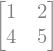

In [7]:
arr=np.array([[1,2],[4,5]])
sp.Matrix(arr)

Similarly, we can convert from SymPy to NumPy using `np.array()`. Note that we also need to specify the data type because SymPy uses its own symbolic data types rather than NumPy's standard integer and floating-point types. Let's take our RREF matrix and convert it to NumPy.

In [8]:
RREF=A.rref()[0]    # Index 0 means we are taking the first item in the list, which is the reduced row echelon form.
np.array(RREF).astype(float)

array([[ 1. ,  0. , -7. ,  0. ,  8. ],
       [ 0. ,  1. ,  2. ,  0. , -2.5],
       [ 0. ,  0. ,  0. ,  1. , -3. ]])

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Solvers</b>
</div></font> 

Numerical solvers typically approximate solutions to equations using various techniques. However, this means that if a system has no solution or have infinitely many solutions, they are not as helpful. For now, we will consider only linear systems that have a unique solution and whose coefficient matrix is a square matrix. For that, we can use `np.linalg.solve` or `la.solve`. These functions treat a linear system as a matrix equation. So, we need to provide a coefficient matrix and a constant vector.

Let's solve the linear system given by the following augmented matrix:
$$\begin{align*}
\left[
\begin{array}{ccc|c}
1 & 4  & -2 & 0  \\ 2 & 2  & -4  & 10  \\  3 & 0 & -2 & 3
\end{array}
\right]
\end{align*}$$

In [2]:
A=np.array([[1,4,-2],[2,2,-4],[3,0,-2]])
b=np.array([0,10,3])
print(la.solve(A,b))

[-1.83333333 -1.66666667 -4.25      ]


SymPy provides `linsolve` function which, in essence, solves the system symbolically, mimicking row operations. It means that the output would look nicer, but symbolic computation are a much slower than numerical methods.

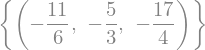

In [4]:
A=sp.Matrix([[1,4,-2],[2,2,-4],[3,0,-2]])
b=sp.Matrix([0,10,3])
sp.linsolve((A,b))

Since SymPy is symbolic mathematics library, it can also handle equations with infinitely many solutions. Let's solve the linear system with the following augmented matrix:
$$\begin{align*}
\left[
\begin{array}{ccccc|c}
1 & 4  & -1 & 2& 1& 0  \\ 2 & 2  & -4  & 2& 0& 10  \\  1 & 0 & -2 & 0&0&3
\end{array}
\right]
\end{align*}$$

In [58]:
A=sp.Matrix([[1,4,-1, 2, 1],[2,2,-4, 2, 0],[1,0,-2, 0, 0]])
b=sp.Matrix([0,10,3])
sp.linsolve((A,b))

We have two free variables, represented by the parameters $\tau_0$ and $\tau_1$. Thus, our solution is 
$${\bf x}= 
\begin{bmatrix}
x_1 \\
x_2\\
x_3\\
x_4\\
x_5
\end{bmatrix}=
\begin{bmatrix}
-19& +4\tau_0 &-2\tau_1  \\
2 &-\tau_0 &\\
 -11 & +2\tau_0& -\tau_1\\
 &\tau_0&\\
 &&\tau_1
\end{bmatrix}
=\begin{bmatrix}
-19 \\
2\\
 -11\\
 0\\
 0
\end{bmatrix}+
\tau_0\begin{bmatrix}
4 \\
-1\\
1\\
 1\\
 0
\end{bmatrix} +
\tau_1\begin{bmatrix}
-2  \\
0\\
 -1\\
 0\\
 1
\end{bmatrix}$$

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Stability and Efficiency of Solvers</b>
</div></font> 

Solving systems of equations using computers comes with several pitfalls. The main issue is that computers cannot represent most real numbers exactly; instead, they approximate them by rounding to a finite number of digits. These approximations introduce small numerical errors. As computations proceed, especially for large systems, such errors can accumulate, potentially leading to inaccurate results. For this reason, it is important to be careful about how we solve systems of equations. Numerical linear algebra studies algorithms that are designed to control the growth of rounding errors and improve computational stability.

One important consideration is the choice of algorithm. For large systems, Gauss–Jordan elimination typically requires more arithmetic operations than Gaussian elimination. Since each operation may introduce a small rounding error, performing more operations increases the opportunity for errors to accumulate. As a result, most numerical solvers are based on Gaussian elimination rather than Gauss–Jordan elimination. For instance, NumPy’s linear system solver does not compute the reduced row echelon form. Instead, it uses LU factorization, a method derived from Gaussian elimination.

Another important technique is partial pivoting. When performing row operations by hand, we often prefer pivots equal to $1$ or $-1$, because they simplify arithmetic. From a numerical perspective, however, this is not always the best choice. To reduce the effects of rounding error, it is generally more stable to choose the entry with the largest absolute value in the current column, among the rows not yet eliminated, as a pivot. This strategy helps avoid dividing by very small numbers, which can amplify numerical errors. NumPy's solver uses partial pivoting as well.


---
**<font color="red">Example 5</font>**

Suppose we want to solve the following system


$$\left\{\begin{array}{l}
  10^{-20}x &+y&=1 \\
 x&+y&=2 
\end{array}\right.$$

The exact solution to this system is $$x=\frac{1}{1-10^{-20}} \quad \text{and} \quad y=\frac{1-2\cdot10^{-20}}{1-10^{-20}}$$ The value $10^{-20}$ is incredibly small. So, our solution can be approximated $$x \approx 1\quad \text{and} \quad y \approx 1$$

Let's solve the system using a solver that employs the technique described above.

In [11]:
A = np.array([[1e-20, 1.0],[1.0,   1.0]])
b = np.array([1.0, 2.0])

print( np.linalg.solve(A, b) )

[1. 1.]


Now, let's try to solve it without partial pivoting. The first step is to eliminate the entry below the pivot by multiplying the first row by $-10^{20}$ and adding the result to the second row:
$$\left[
\begin{array}\fbox{\begin{array}{cc|c}
10^{-20} & 1  & 1 \\ 1 & 1  & 2
\end{array}}\end{array}
\right]
\stackrel{\color{HotPink}{R_2 + (-10^{20}) R_1}}{\sim} 
\left[
\begin{array}\fbox{\begin{array}{cc|c}
10^{-20} & 1  & 1   \\  0 & 1-10^{20} & 2-10^{20}
\end{array}}\end{array}
\right]$$

Let's see what we get:

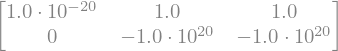

In [12]:
As=sp.Matrix(A)
bs=sp.Matrix(b)
Aug=As.row_join(bs)
Aug[1,:]=Aug[1,:]-10**(20)*Aug[0,:]
Aug

If you compare this result with the one we obtained manually above, you should notice that we are in trouble now. The last two columns appear identical, even though they should be different based on our earlier work. The reason is that the numbers $1-10^{20}$ and $2-10^{20}$ are both extremely large numbers that differ only by $1$. Relative to the size of these numbers, this difference is negligible and is therefore lost due to rounding. Although this approximation seems harmless, it leads to a significant error later in the computation.

Let us continue the calculation to see the effect.  We scale the second row so that the leading value equals $1$. 

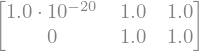

In [13]:
Aug[1,:]=Aug[1,:]/Aug[1,1]
Aug

So far, so good. We can see that $y=1$, which is a correct approximation. Next, we add the negative of the second row to the first row.

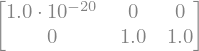

In [14]:
Aug[0,:]=Aug[0,:]-Aug[1,:]
Aug

Finally, we scale the first row to make the pivot equal 1.

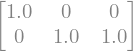

In [15]:
Aug[0,:]=Aug[0,:]/Aug[0,0]
Aug

As you can see, we obtained $x=0$, which is clearly far from the correct answer.

Now compare this result with the same sequence of steps performed after first swapping the rows. As you can see, the row swap prevents the loss of significant digits and leads to a much more accurate result.

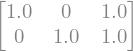

In [16]:
As=sp.Matrix(A)
bs=sp.Matrix(b)
Aug=As.row_join(bs)
Aug.row_swap(0,1)
Aug[1,:]=Aug[1,:]-10**(-20)*Aug[0,:]
Aug[1,:]=Aug[1,:]/Aug[1,1]
Aug[0,:]=Aug[0,:]-Aug[1,:]
Aug[0,:]=Aug[0,:]/Aug[0,0]
Aug

######
<font color="#0fbf0f" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Exercises</b>
</div></font> 

**1.**
>Which of the following matrices are in an echelon form?
>$$\begin{bmatrix} 2 & 3 \\ 0 & 0 \end{bmatrix}, \begin{bmatrix} 0 & 1 \\ 0 & 0 \end{bmatrix}, \begin{bmatrix} 0 & 3 & 4 \\ 0 & 1 & 1\end{bmatrix}, \begin{bmatrix} 0 & 3 & 12\\ 0 & 0 & 3\end{bmatrix}, \begin{bmatrix} 0 & 0 & 1 \\ 1 & 0 & 1\end{bmatrix}, \begin{bmatrix} 1 & 0 & 1 & 0 & 0 \\ 0 & 1 & 5 & 0 & 1\\ 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 1 & 0 & 1\end{bmatrix},\begin{bmatrix} 1 & 0 & 1 & 0 & 0 \\ 0 & 0 & 5 & 0 & 1\\ 0 & 0 & 0 & 1 & 1 \\ 0 & 0 & 0 & 0 & 1\end{bmatrix}$$

**2.**
>Which of the following matrices are in the reduced row echelon form?
>$$\begin{bmatrix} 1 & 3 \\ 0 & 0 \end{bmatrix}, \begin{bmatrix} 0 & 1 \\ 0 & 0 \end{bmatrix}, \begin{bmatrix} 0 & 0 & 1 \\ 0 & 1 & 0\end{bmatrix}, \begin{bmatrix} 0 & 3 & 12\\ 0 & 0 & 3\end{bmatrix}, \begin{bmatrix} 1 & 3 & 0 \\ 0 & 0 & 1\end{bmatrix}, \begin{bmatrix} 1 & 0 & 1 & 0 & 0 \\ 0 & 1 & 5 & 0 & 0\\ 0 & 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 0 & 1\end{bmatrix},\begin{bmatrix} 1 & 3 & 0 & 0 & 0 \\ 0 & 0 & 1 & 0 & 4\\ 0 & 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & 0 & 0\end{bmatrix}$$

**3.**
> Use row reduction to find the solution set to a linear system given by the following **augmented** matrices. Leave your answer in vector parametric form.  
> ***a.*** $ \begin{bmatrix} 1& 2 & 4 & 1 \\ 2 & 2 & 4 & 2 \end{bmatrix};  \quad \quad$
> ***b.*** $ \begin{bmatrix} 0& 2 & 3 & 1 \\ 2 & 4 & 4 & 6  \\ 1 & 1 & 1 & 3 \end{bmatrix};  \quad \quad$
> ***c.*** $ \begin{bmatrix} 1& 2 & 1 & 0 \\ 2 & 4 & 4 & 6  \\ 1 & 2 & 2 & 2 \end{bmatrix};  \quad \quad$
> ***d.*** $\begin{bmatrix} 1 & 0 & 1 & 0 & 0 \\ 0 & 1 & 5 & 0 & 1\\ 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 1 & 0 & 1\end{bmatrix}$

**4.**
> Express vector ${\bf y}=\begin{bmatrix}1 \\ 11 \end{bmatrix} $ as a linear combination of vectors ${\bf v}_1=\begin{bmatrix}1 \\ -1\end{bmatrix}$ and ${\bf v}_2=\begin{bmatrix}1 \\ 3\end{bmatrix}$.

**5.**
> Express vector ${\bf y}=\begin{bmatrix}10 \\ -1 \\-1 \end{bmatrix} $ as a linear combination of vectors ${\bf v}_1=\begin{bmatrix}1 \\ 0 \\1 \end{bmatrix}$,  ${\bf v}_2=\begin{bmatrix}-2 \\ 1 \\ 2 \end{bmatrix}$ and ${\bf v}_3=\begin{bmatrix}3 \\ 1 \\ 0 \end{bmatrix}$.

***6.*** 
> Let $A=\begin{bmatrix} 1 & 3 & -1 \\ 2& -1 & 3 \\ 0 & 1 & 1 \end{bmatrix} $ and ${\bf b}=\begin{bmatrix}-4 \\ 0 \\ 2 \end{bmatrix}$.  
> ***a.*** Solve the matrix equation $A{\bf x}={\bf b}$ using row operations.  
> ***b.*** Solve the matrix equation $A{\bf x}={\bf b}$ using NumPy.

***7.***
> Let $A=\begin{bmatrix} 1 & 2 & -2 \\ 1& 3 & 5 \\ -1 & 0 & 1 \end{bmatrix} $ and ${\bf b}=\begin{bmatrix}0 \\ -10 \\ -5 \end{bmatrix}$.  
> ***a.*** Solve the matrix equation $A{\bf x}={\bf b}$ using row operations.  
> ***b.*** Solve the matrix equation $A{\bf x}={\bf b}$ using NumPy.

***8.***
>A linear system is **underdetermined** if it has fewer equations than unknowns. If an underdetermined linear system is consistent, why must it have infinitely many solutions?

***9.***
>A linear system is **overdetermined** if it has more equations than unknowns. Can such a system be consistent?

***10.*** 

> Suppose your data are represented by points in the plane. An **interpolating polynomial** is a polynomial that goes through every point of the data. Find the interpolating polynomial $p(x)=a_0+a_1x+a_2x^2$ for the data $(1,-2)$, $(2, -1)$, $(3,4)$.  
> **Hint:** All three points must satisfy the polynomial equation. So, $$ a_0+ a_1 (1) + a_2(1^2)=-2$$ $$a_0+ a_1 (2) + a_2(2^2)=-1$$ $$a_0+ a_1 (3) + a_2(3^2)=4$$